In [1]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np
import os
from tensorflow.keras.utils import to_categorical

In [35]:
data_path = 'input/'

train_path = os.path.join(data_path, 'train_val')
test_path = os.path.join(data_path, 'test')

train_images_path = os.path.join(train_path, 'images')
train_masks_path = os.path.join(train_path, 'masks')

test_images_path = os.path.join(test_path, 'images')
test_masks_path = os.path.join(test_path, 'masks')

class_names = [
    'Background (waterbody)', 'Human divers', 'Aquatic plants and sea-grass',
    'Wrecks and ruins', 'Robots (AUVs/ROVs/instruments)', 'Reefs and invertebrates',
    'Fish and vertebrates', 'Sea-floor and rocks',
]
num_classes = len(class_names)
class_codes = {
    0: [0, 0, 0],  # Black
    1: [0, 0, 1],  # Blue
    2: [0, 1, 0],  # Green
    3: [0, 1, 1],  # Sky
    4: [1, 0, 0],  # Red
    5: [1, 0, 1],  # Pink
    6: [1, 1, 0],  # Yellow
    7: [1, 1, 1],  # White
}

In [3]:
def list_files(path):
    content = os.listdir(path)
    files = [f for f in content if os.path.isfile(os.path.join(path, f))]
    return files


train_images = list_files(train_images_path)
train_masks = list_files(train_masks_path)

test_images = list_files(test_images_path)
test_masks = list_files(test_masks_path)

print('Train images:', len(train_images))
print('Train masks:', len(train_masks))
print('Test images:', len(test_images))
print('Test masks:', len(test_masks))
print(f'Number of classes: {num_classes}')

Train images: 1525
Train masks: 1525
Test images: 110
Test masks: 110
Number of classes: 8


Image shape: (480, 640, 3)
Mask shape: (480, 640, 3)
Image pixel values range [0, 255]
Mask pixel values range [0, 255]


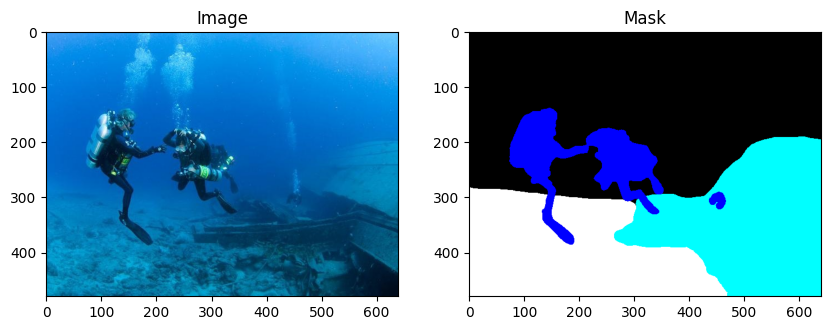

In [4]:
def read_image(path):
    image = cv.imread(path, cv.IMREAD_COLOR)
    image = cv.cvtColor(image, cv.COLOR_BGR2RGB)
    return image


image = read_image(os.path.join(train_images_path, train_images[0]))
mask = read_image(os.path.join(train_masks_path, train_masks[0]))

print('Image shape:', image.shape)
print('Mask shape:', mask.shape)
print(f'Image pixel values range [{np.min(image)}, {np.max(image)}]')
print(f'Mask pixel values range [{np.min(mask)}, {np.max(mask)}]')

plt.figure(figsize=(10, 10))
plt.subplot(121)
plt.imshow(image)
plt.title('Image')
plt.subplot(122)
plt.imshow(mask)
plt.title('Mask')
plt.show()

In [5]:
def load_data(data_folder, normalize=True, resize=(640, 480)):
    images_folder = os.path.join(data_folder, 'images')
    masks_folder = os.path.join(data_folder, 'masks')

    image_names = os.listdir(images_folder)
    mask_names = os.listdir(masks_folder)

    images = []
    masks = []

    for image_name, mask_name in zip(image_names, mask_names):
        image_path = os.path.join(images_folder, image_name)
        mask_path = os.path.join(masks_folder, mask_name)

        # Filter out folders
        if not os.path.isfile(image_path) or not os.path.isfile(mask_path):
            continue

        # Load the image and mask
        image = cv.imread(image_path)
        mask = cv.imread(mask_path)

        # Resize the images to same size
        if resize is not None:
            image = cv.resize(image, resize, interpolation=cv.INTER_NEAREST)
            mask = cv.resize(mask, resize, interpolation=cv.INTER_NEAREST)

        # Convert the images to RGB
        image = cv.cvtColor(image, cv.COLOR_BGR2RGB)
        mask = cv.cvtColor(mask, cv.COLOR_BGR2RGB)

        # Normalize the images
        if normalize:
            image = image / 255.0
            mask = mask / 255.0

        images.append(image)
        masks.append(mask)

    return images, masks


train_images, train_masks = load_data(train_path, normalize=False, resize=None)
test_images, test_masks = load_data(test_path, normalize=False, resize=None)

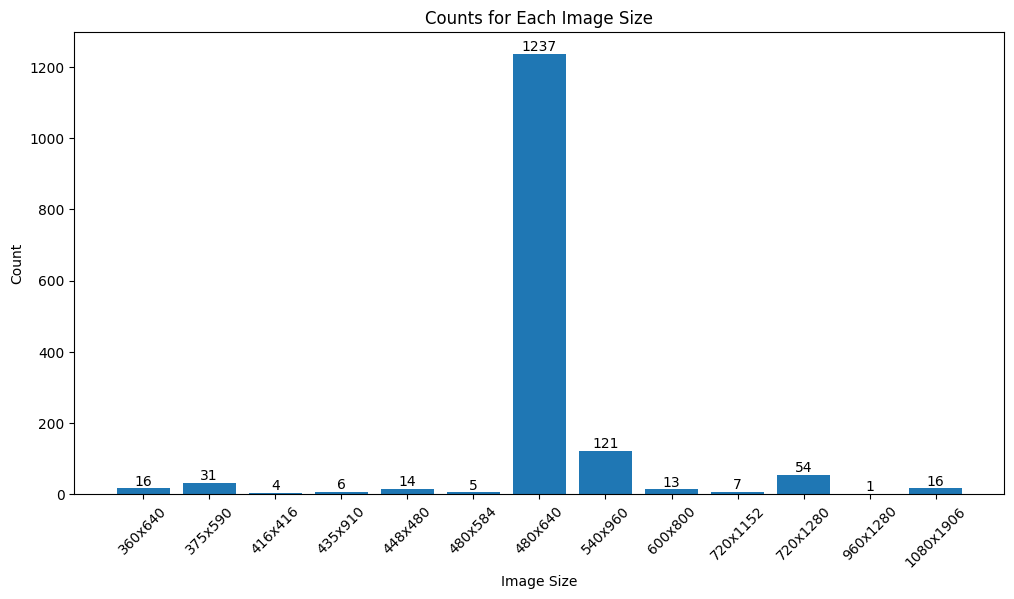

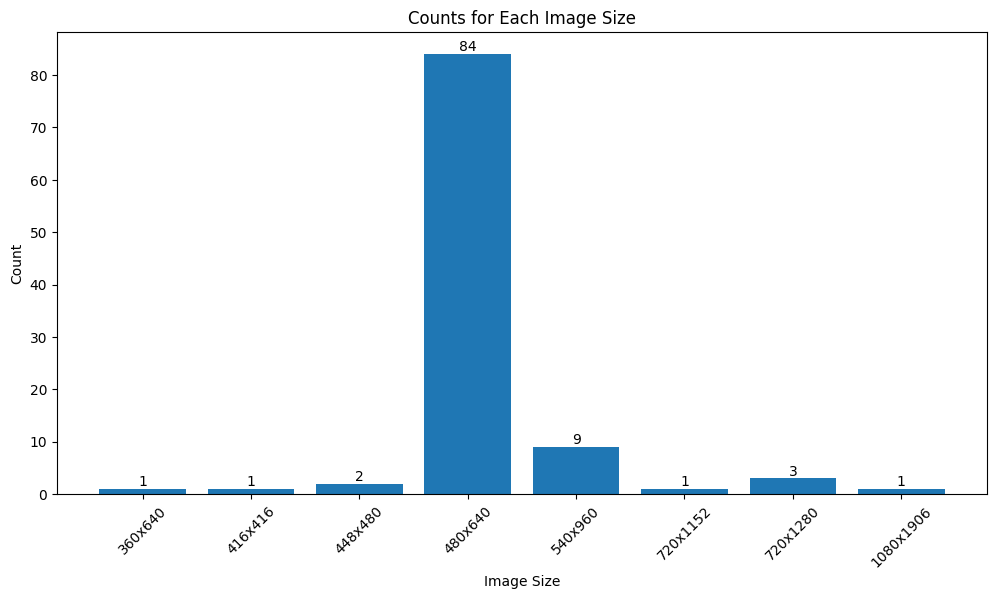

In [6]:
def plot_sizes_histogram(images):
    # Get the unique image sizes and their counts
    sizes = [image.shape for image in images]
    sizes, counts = np.unique(np.array(sizes), axis=0, return_counts=True)

    # Plot the histogram
    size_labels = [f'{s[0]}x{s[1]}' for s in sizes]
    plt.figure(figsize=(12, 6))
    bars = plt.bar(size_labels, counts)
    plt.xlabel('Image Size')
    plt.ylabel('Count')
    plt.title('Counts for Each Image Size')
    plt.xticks(rotation=45)

    # Add count labels to each bar
    for bar, value in zip(bars, counts):
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width() / 2, height, value, ha='center', va='bottom')
    plt.show()


plot_sizes_histogram(train_images)
plot_sizes_histogram(test_images)

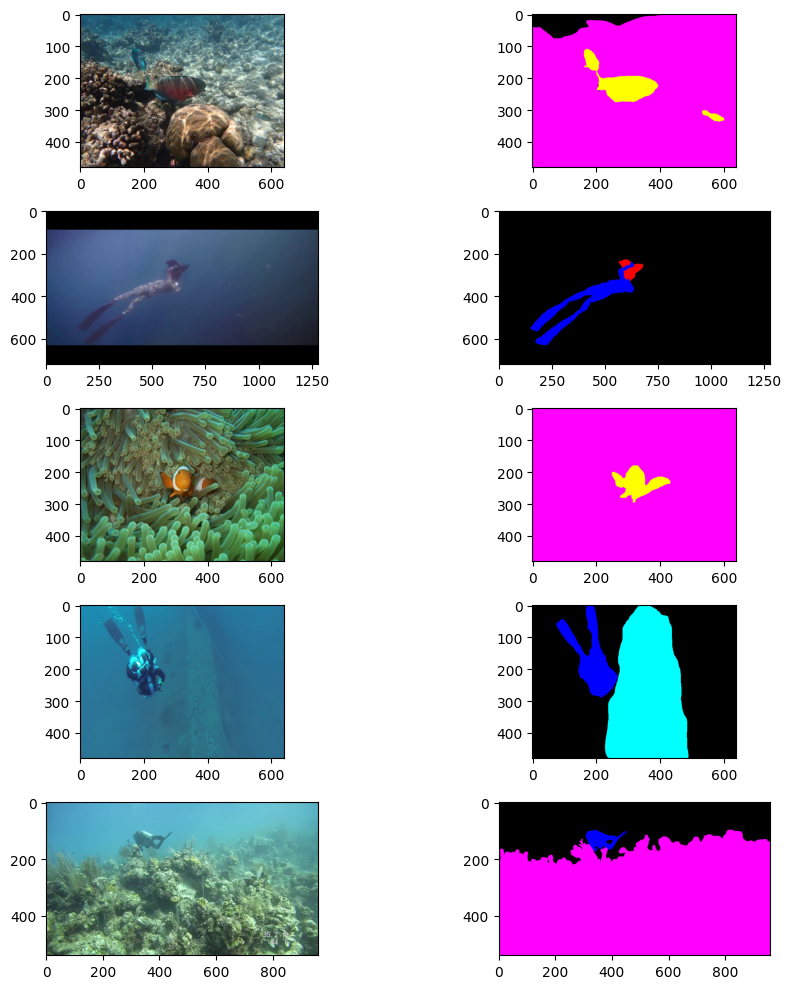

In [10]:
def plot_images(images, masks, n=5):
    fig, axes = plt.subplots(n, 2, figsize=(10, 10))

    # Randomly select n images and masks
    sample = np.random.randint(0, len(images), n)
    for i, j in enumerate(sample):
        axes[i, 0].imshow(images[j])
        axes[i, 1].imshow(masks[j])

    plt.tight_layout()
    plt.show()


plot_images(train_images, train_masks)

Mask shape: (480, 640)
Unique pixel values: [0 1 3 7]
Mask pixel values range [0, 7]


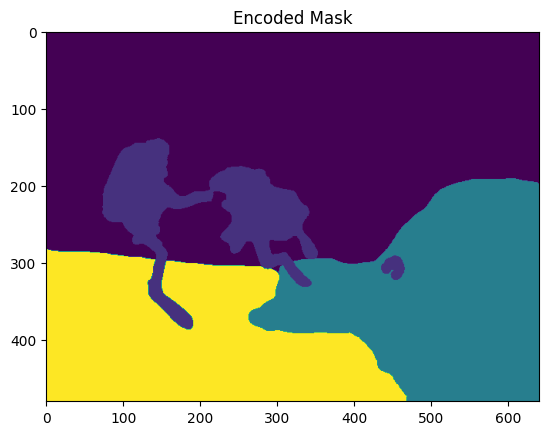

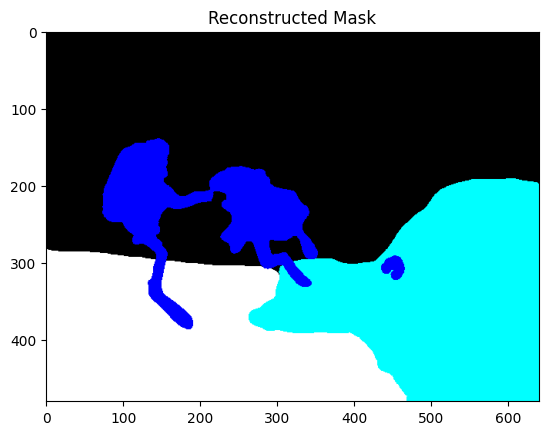

In [79]:
def rgb_to_label(image, label_codes, one_hot=True):
    label_image = np.zeros((image.shape[0], image.shape[1]), dtype=np.uint8)
    # Assigns each pixel a label from [0, num_classes - 1]
    for class_num, color in label_codes.items():
        label_image[np.all(image == color, axis=-1)] = class_num
    # Converts labeled image from (H, W) to (H, W, num_classes),
    # where each pixel is a one-hot vector (e.g. [2] => [0, 0, 1, 0, 0, 0, 0, 0])
    if one_hot:
        n_classes = len(label_codes)
        label_image = to_categorical(label_image, n_classes)
    return label_image


def label_to_rgb(image, label_codes, one_hot=True):
    rgb_image = np.empty((image.shape[0], image.shape[1], 3), dtype=np.float32)
    # Assigns each pixel a color from label_codes
    if one_hot:
        for class_num, color in label_codes.items():
            rgb_image[image[:, :, class_num] == 1] = color
    else:
        for class_num, color in label_codes.items():
            rgb_image[image == class_num] = color
    return rgb_image


mask = (train_masks[0] / 255.0).astype(np.float32)

mask = rgb_to_label(mask, class_codes, one_hot=False)
unique_pixels = np.unique(mask)
print('Mask shape:', mask.shape)
print('Unique pixel values:', unique_pixels)
print(f'Mask pixel values range [{np.min(mask)}, {np.max(mask)}]')
plt.imshow(mask)
plt.title('Encoded Mask')
plt.show()

mask = label_to_rgb(mask, class_codes, one_hot=False)
plt.imshow(mask)
plt.title('Reconstructed Mask')
plt.show()

Mask shape: (480, 640, 8)
Mask pixel values range [0.0, 1.0]
Unique pixel values: [0. 1.]


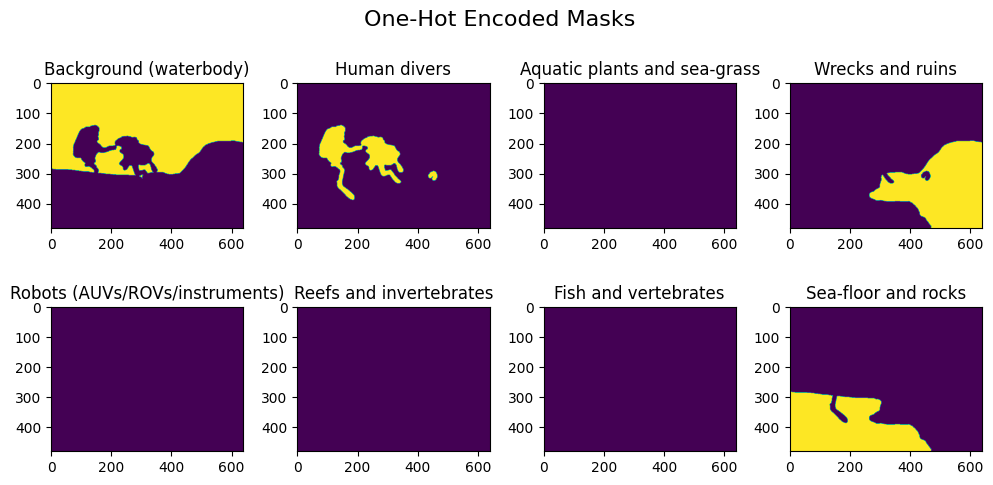

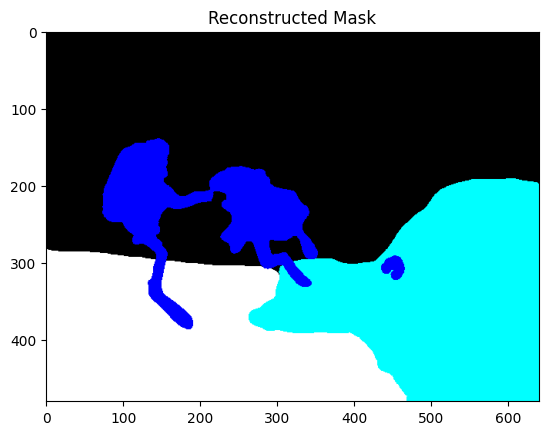

In [82]:
mask = (train_masks[0] / 255.0).astype(np.float32)

mask = rgb_to_label(mask, class_codes, one_hot=True)
unique_pixels = np.unique(mask)
print('Mask shape:', mask.shape)
print(f'Mask pixel values range [{np.min(mask)}, {np.max(mask)}]')
print('Unique pixel values:', unique_pixels)

# plot images in 4x2 grid
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
fig.suptitle('One-Hot Encoded Masks', fontsize=16)
for i, ax in enumerate(axes.flat):
    ax.imshow(mask[:, :, i])
    ax.set_title(class_names[i])
plt.tight_layout()
plt.show()

mask = label_to_rgb(mask, class_codes)
plt.imshow(mask)
plt.title('Reconstructed Mask')
plt.show()